Epoch 1/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6006 - loss: 1.2060 - val_accuracy: 0.8050 - val_loss: 0.7526
Epoch 2/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7500 - loss: 0.7043 - val_accuracy: 0.8200 - val_loss: 0.7377
Epoch 3/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8106 - loss: 0.5708 - val_accuracy: 0.8100 - val_loss: 0.7147
Epoch 4/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8239 - loss: 0.5050 - val_accuracy: 0.8300 - val_loss: 0.6998
Epoch 5/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8283 - loss: 0.4661 - val_accuracy: 0.8150 - val_loss: 0.6958
Epoch 6/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8606 - loss: 0.4021 - val_accuracy: 0.8150 - val_loss: 0.7686
Epoch 7/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8694 - loss: 0.3573 - val_accuracy: 0.8400 - val_loss: 0.6982
Epoch 8/50
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8800 - loss: 0.3153 - val_accuracy: 0.8150 - val_loss:

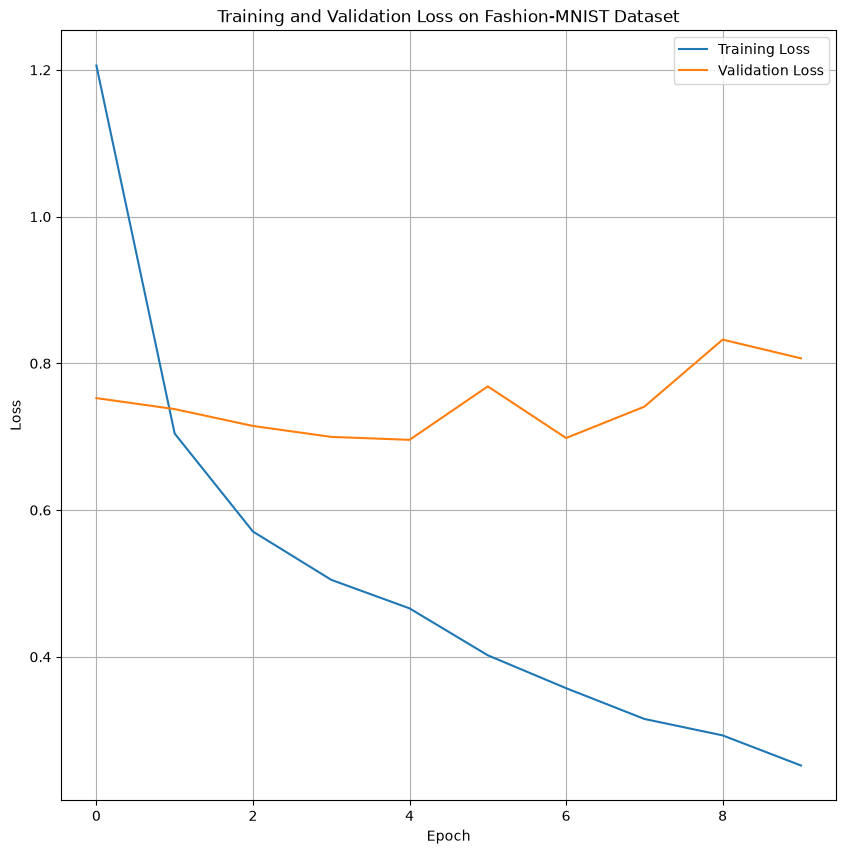

MC Dropout accuracy: 81.25%


In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# load training and test data from Fashion-MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# select only the first 2000 training samples
(X_train,
 y_train) = (X_train[:2000],
             y_train[:2000])

# select only the first 400 test samples
(X_test,
 y_test) = (X_test[:400],
            y_test[:400])

# calculate per-pixel mean and standard deviation from training data
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0) + 1e-8 # avoid division by zero

# standardize both datasets using training statistics
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# build neural network with three hidden layers
model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28)),

    tf.keras.layers.Flatten(), # convert to 1D

    # three hidden layers with 100 neurons each, using SELU and LeCun initialization
    # AlphaDropout preservers activation statistics to support self-normalization
    tf.keras.layers.Dense(100, activation="selu", kernel_initializer="lecun_normal"),
    tf.keras.layers.AlphaDropout(0.1),
    tf.keras.layers.Dense(100, activation="selu", kernel_initializer="lecun_normal"),
    tf.keras.layers.AlphaDropout(0.1),
    tf.keras.layers.Dense(100, activation="selu", kernel_initializer="lecun_normal"),
    tf.keras.layers.AlphaDropout(0.1),

    # output layer with one neuron for each category
    tf.keras.layers.Dense(10, activation="softmax")
])

# configure Nadam optimizer with a learning rate of 0.001
optimizer = tf.keras.optimizers.Nadam(learning_rate=0.001)

# compile model with Nadam optimizer, loss function and accuracy metric
model.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ensures that training is stopped if validation loss does not improve for 5 consecutive epochs,
# and restores the best weights
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# fit the model using 10% of training data as validation
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop]
)

# evaluate model on test data and report accuracy in percentage
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_acc * 100:.2f}%")

plt.figure(figsize=(10, 10))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss on Fashion-MNIST Dataset")
plt.legend()
plt.grid(True)
plt.show()

# perform 20 stochastic forward passes with AlphaDropout enabled during inference
mc_predict = []

for _ in range(20):
    predictions = model(X_test, training=True)
    mc_predict.append(predictions.numpy())

# average predicted class probabilities
mean_predicts = np.mean(mc_predict, axis=0)

# select the class with the highest average probability
pred_classes = np.argmax(mean_predicts, axis=1)

# calculate MC dropout accuracy
mc_acc = np.mean(pred_classes == y_test)

print(f"MC Dropout accuracy: {mc_acc * 100:.2f}%")
